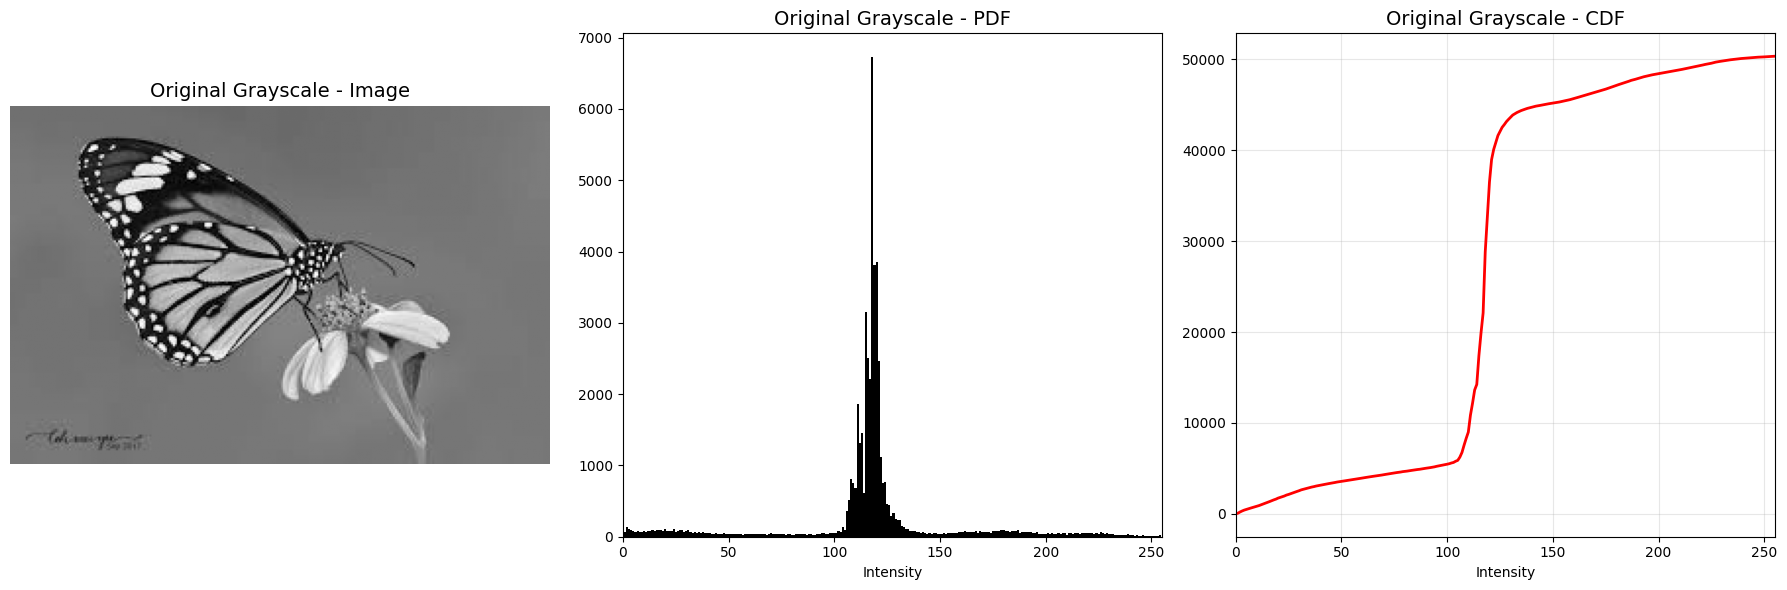

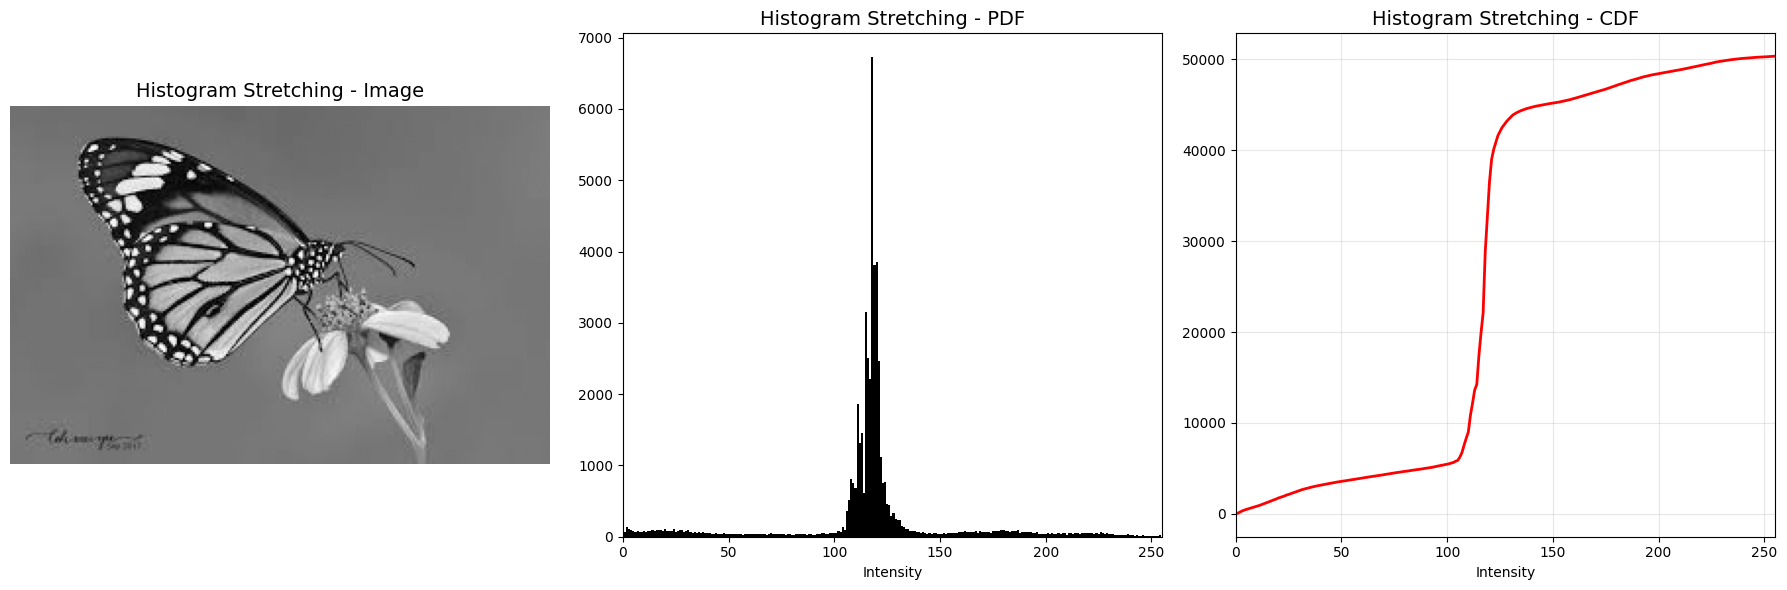

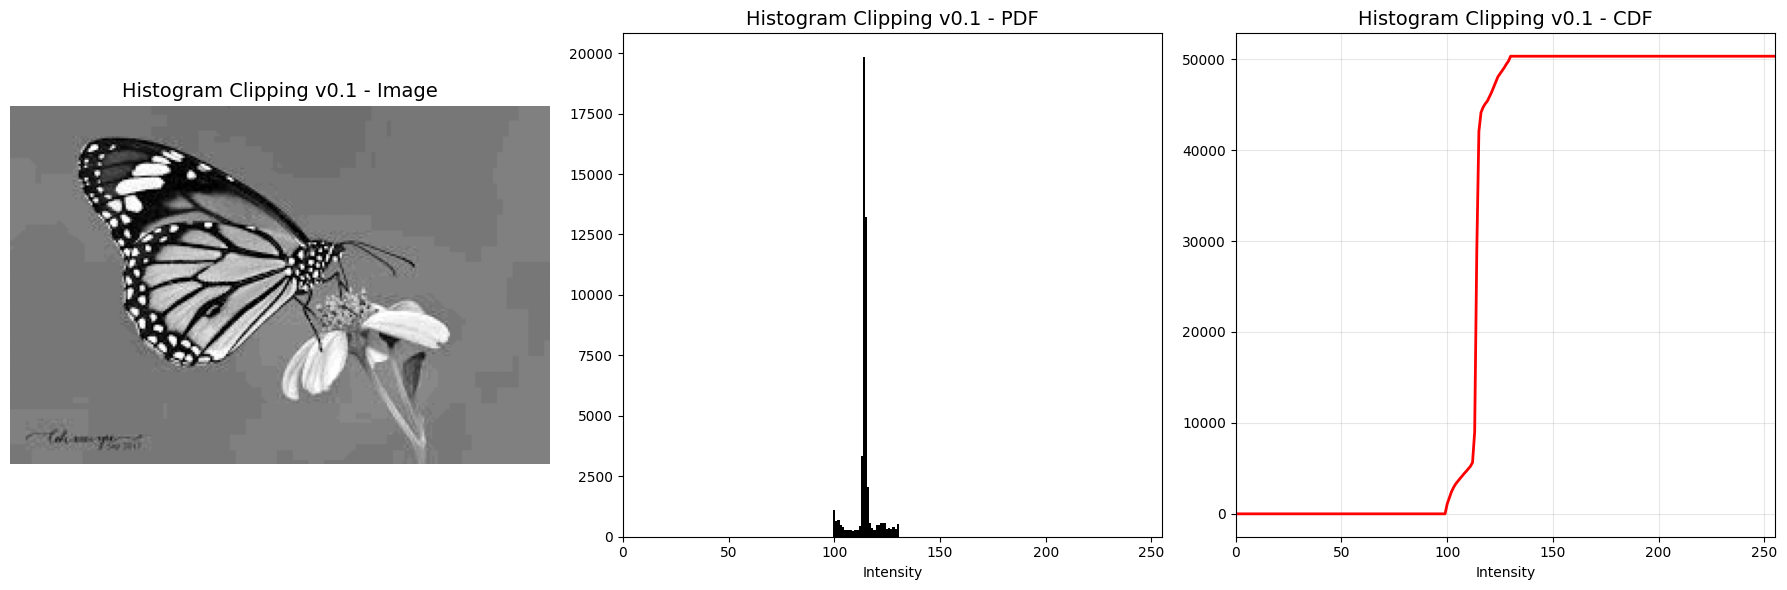

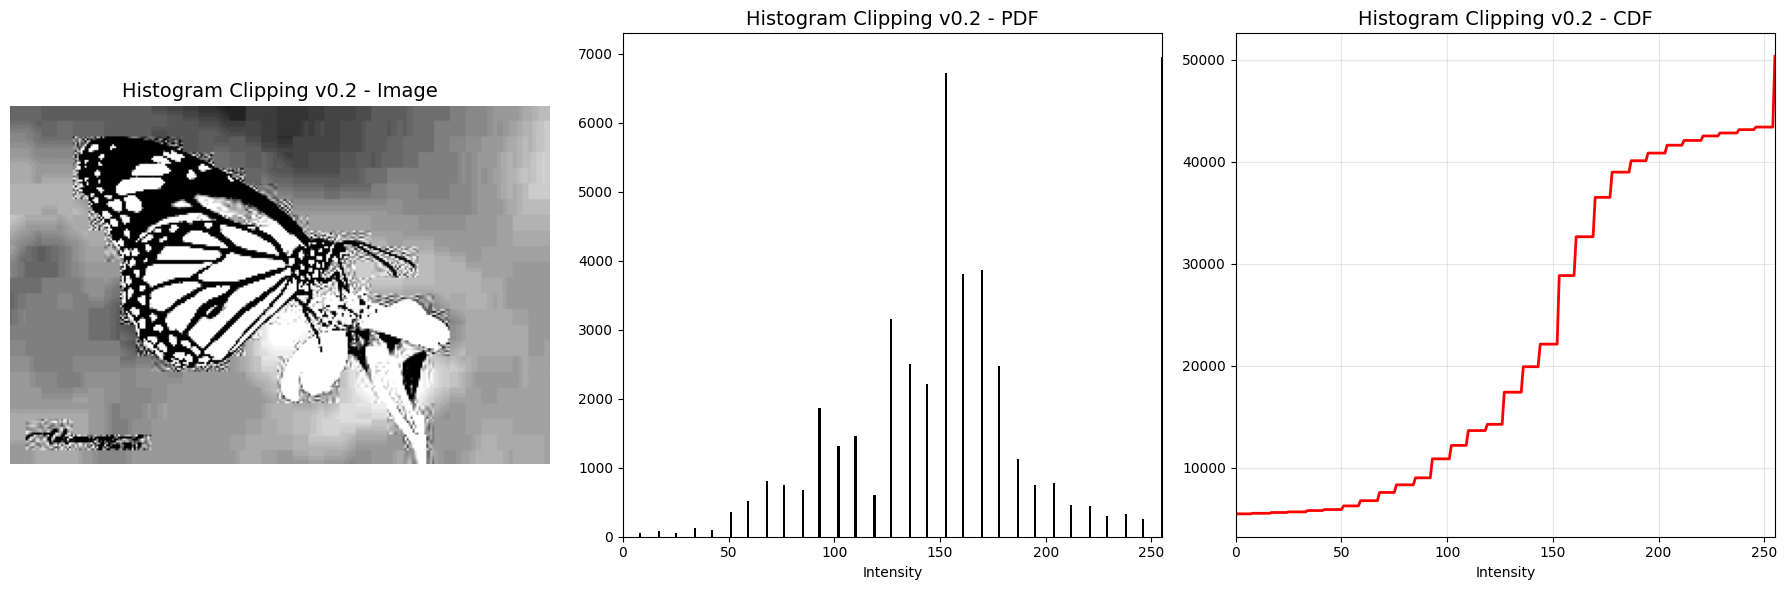

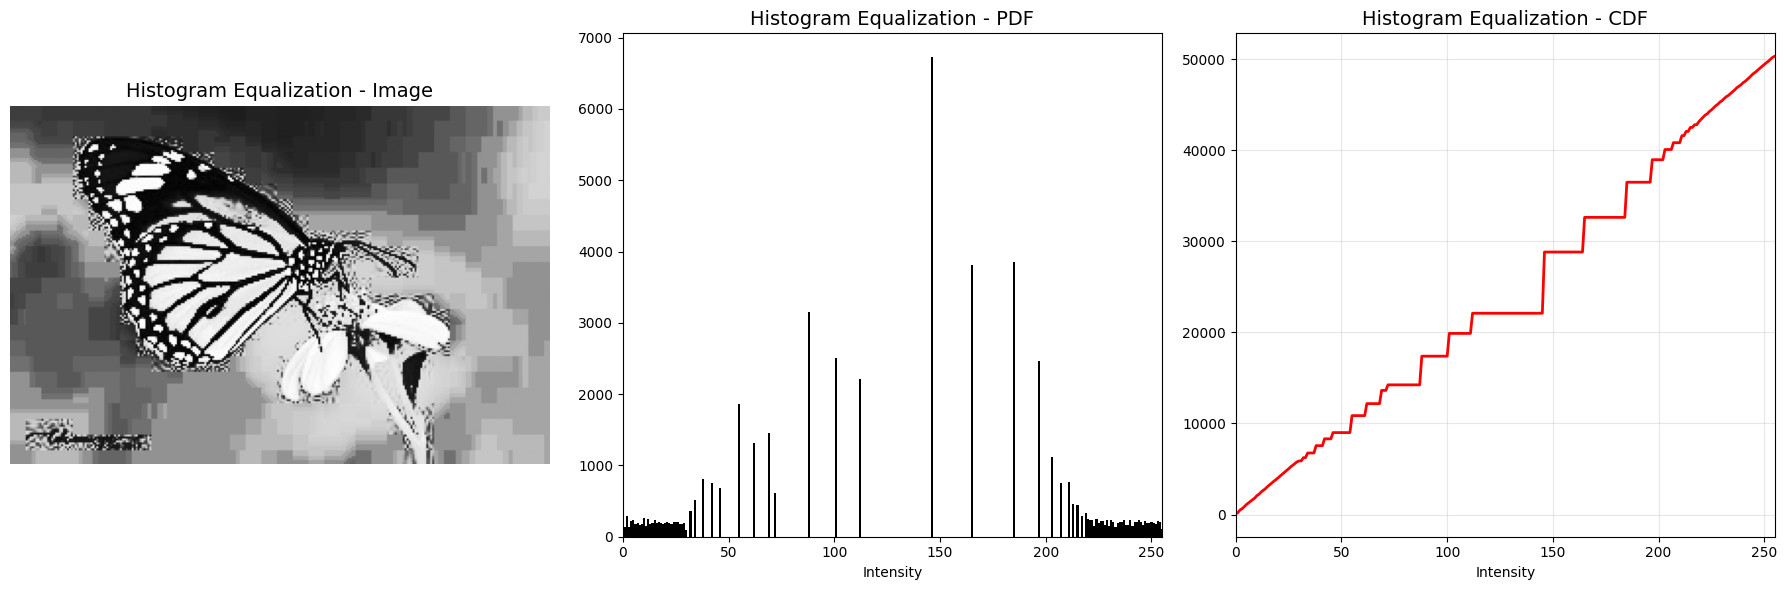

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

img_color = cv.imread('Butterfly.jpg')
assert img_color is not None, "Check path!"

gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)
h, w = gray.shape

def PDF(img):
    pdf = np.zeros(256, dtype=np.float64)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            pdf[img[i,j]] += 1
    return pdf

def CDF(pdf):
    cdf = np.zeros(256, dtype=np.float64)
    cdf[0] = pdf[0]
    for i in range(1, 256):
        cdf[i] = cdf[i-1] + pdf[i]
    return cdf

def show_result(img_processed, title):
    pdf = PDF(img_processed)
    cdf = CDF(pdf)
    # print(pdf[0])
    # print(pdf[-1])
    
    plt.figure(figsize=(18, 6))
    
    plt.subplot(1, 3, 1)
    plt.imshow(img_processed, cmap='gray')
    plt.title(f'{title} - Image', fontsize=14)
    plt.axis('off')
    
    # PDF
    plt.subplot(1, 3, 2)
    plt.bar(np.arange(256), pdf, width=1.0, color='black')
    plt.title(f'{title} - PDF', fontsize=14)
    plt.xlim(0, 255)
    plt.xlabel('Intensity')
    
    # CDF
    plt.subplot(1, 3, 3)
    plt.plot(cdf, color='red', linewidth=2)
    plt.title(f'{title} - CDF', fontsize=14)
    plt.xlim(0, 255)
    plt.xlabel('Intensity')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

show_result(gray, "Original Grayscale")

# Histogram Stretching
min_val = np.min(gray)
max_val = np.max(gray)
stretched = np.clip((gray.astype(np.float32) - min_val) * (255.0 / (max_val - min_val)), 0, 255).astype(np.uint8)

show_result(stretched, "Histogram Stretching")

OUT_MIN, OUT_MAX = 100.0, 130.0

f_low = np.percentile(gray, 1)
f_high = np.percentile(gray, 99)

# map to [0,1]
scaled = (gray.astype(np.float32) - f_low) / (f_high - f_low)
scaled = np.clip(scaled, 0.0, 1.0)

# map to [OUT_MIN, OUT_MAX]
mapped = (scaled * (OUT_MAX - OUT_MIN) + OUT_MIN).astype(np.uint8)
show_result(mapped, "Histogram Clipping v0.1")

MIN, MAX = 100, 130
clipped = np.clip((gray.astype(np.float32) - MIN) / (MAX - MIN) * 255, 0, 255).astype(np.uint8)
show_result(clipped, "Histogram Clipping v0.2")

# Histogram Equalization
equalized = cv.equalizeHist(gray)

show_result(equalized, "Histogram Equalization")